# 02 - Exploratory Data Analysis: Kaub water level

**Goal.** Understand the daily Kaub gauge record and its weather drivers well enough to
choose features and a sensible baseline for the load-planning model.

**Input.** `data/processed/kaub_water_weather_daily.csv`, produced by
`01. data_import.ipynb` (WSV 15-minute gauge readings + Open-Meteo hourly reanalysis,
aggregated to daily).

**Known caveats carried in from notebook 01 - read before trusting any lag result:**

1. *Timestamps are timezone-naive.* The gauge series is Europe/Berlin wall-clock
   (DST-aware) while the Open-Meteo response is a flat UTC+1 grid. The hourly merge joins
   them on nominal labels, so for roughly seven months a year each water reading is paired
   with weather from one hour later. Daily means absorb most of this, but any *sub-daily*
   lead/lag conclusion is unreliable until both sides are localised to UTC.
2. *The first day is partial.* Both sources start at 01:00 on 2000-01-01, so that day
   aggregates 23 hours. It is detected and dropped below rather than silently averaged.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 130)

DAILY_PATH = "../data/processed/kaub_water_weather_daily.csv"
HOURLY_PATH = "../data/processed/kaub_water_weather_hourly.csv"
RAW_PATH = "../data/raw/water_level_15min_kaub.csv"

TARGET = "water_level_mean"
WEATHER_COLS = [
    "temperature_mean", "humidity_mean", "precipitation_sum",
    "rain_sum", "snowfall_sum", "pressure_mean", "wind_speed_mean",
]

# parse_dates is essential: without it `date` loads as object and every
# .dt accessor, resample and rolling window below fails.
df = pd.read_csv(DAILY_PATH, parse_dates=["date"])
df.head()

,date,water_level_mean,water_level_min,water_level_max,temperature_mean,humidity_mean,precipitation_sum,rain_sum,snowfall_sum,pressure_mean,wind_speed_mean
0,2000-01-01,438.989130,420.75,458.25,3.286957,97.434783,1.7,1.7,0.0,1025.256522,7.773913
1,2000-01-02,401.260417,385.25,419.00,3.979167,96.291667,0.0,0.0,0.0,1030.475000,6.095833
2,2000-01-03,367.989583,359.25,383.50,2.350000,94.458333,0.0,0.0,0.0,1028.470833,11.875000
3,2000-01-04,346.093750,337.00,358.75,5.470833,91.791667,0.8,0.8,0.0,1020.412500,18.445833
4,2000-01-05,327.968750,320.00,337.00,5.495833,89.708333,0.2,0.2,0.0,1021.983333,10.237500


## 1. Integrity checks

Everything downstream assumes a gap-free, unique, sorted daily index. Verify it once, here.

In [2]:
print("shape:", df.shape)
print("date range:", df["date"].min().date(), "->", df["date"].max().date())
print()
print(df.dtypes.to_string())
print()

expected_days = pd.date_range(df["date"].min(), df["date"].max(), freq="D")
checks = {
    "duplicate dates": int(df["date"].duplicated().sum()),
    "missing calendar days": len(expected_days.difference(df["date"])),
    "rows with any NaN": int(df.isna().any(axis=1).sum()),
    "dates sorted ascending": bool(df["date"].is_monotonic_increasing),
}
for name, value in checks.items():
    print(f"{name:24s}: {value}")

shape: (9741, 11)
date range: 2000-01-01 -> 2026-09-01

date                 datetime64[us]
water_level_mean            float64
water_level_min             float64
water_level_max             float64
temperature_mean            float64
humidity_mean               float64
precipitation_sum           float64
rain_sum                    float64
snowfall_sum                float64
pressure_mean               float64
wind_speed_mean             float64

duplicate dates         : 0
missing calendar days   : 0
rows with any NaN       : 0
dates sorted ascending  : True


In [3]:
df.isna().sum().to_frame("n_missing").T

,date,water_level_mean,water_level_min,water_level_max,temperature_mean,humidity_mean,precipitation_sum,rain_sum,snowfall_sum,pressure_mean,wind_speed_mean
n_missing,0,0,0,0,0,0,0,0,0,0,0


### 1.1 Daily completeness

A daily mean over 23 hours and a daily mean over 24 hours are not the same quantity, and a
`precipitation_sum` over a partial day is simply wrong. Recover the true hour count per day
from the hourly file instead of assuming 24.

In [4]:
hours_per_day = (
    pd.read_csv(HOURLY_PATH, usecols=["date"])
      .groupby("date")
      .size()
      .rename("hours_available")
)
hours_per_day.index = pd.to_datetime(hours_per_day.index)

df = df.merge(hours_per_day, left_on="date", right_index=True, how="left")

print(df["hours_available"].value_counts().to_string())
incomplete = df.loc[df["hours_available"] != 24]
print(f"\nincomplete days: {len(incomplete)}")
incomplete[["date", "hours_available", TARGET, "precipitation_sum"]]

hours_available
24    9740
23       1

incomplete days: 1


,date,hours_available,water_level_mean,precipitation_sum
0,2000-01-01,23,438.98913,1.7


In [5]:
before = len(df)
df = (
    df.loc[df["hours_available"] == 24]
      .drop(columns="hours_available")
      .reset_index(drop=True)
)
print(f"dropped {before - len(df)} incomplete day(s); {len(df)} days remain")

# still contiguous after the drop?
assert df["date"].diff().dropna().eq(pd.Timedelta(days=1)).all(), "gap introduced by the drop"
print("daily index is contiguous:", df["date"].min().date(), "->", df["date"].max().date())

dropped 1 incomplete day(s); 9740 days remain
daily index is contiguous: 2000-01-02 -> 2026-09-01


### 1.2 Internal consistency of the gauge aggregates

`water_level_min <= water_level_mean <= water_level_max` must hold for every row. A
violation would mean the min/max and the mean were computed over different sets of rows.

In [6]:
violations = df[(df["water_level_min"] > df[TARGET]) | (df[TARGET] > df["water_level_max"])]
print("rows violating min <= mean <= max:", len(violations))

df["water_level_range"] = df["water_level_max"] - df["water_level_min"]
print()
print("intraday range (cm):")
print(df["water_level_range"].describe().to_string())

rows violating min <= mean <= max: 0

intraday range (cm):
count    9740.000000
mean       13.128080
std        14.112287
min         1.000000
25%         5.250000
50%         8.500000
75%        15.062500
max       188.500000


## 2. The target: daily mean water level

In [7]:
df[TARGET].describe().to_frame().T

,count,mean,std,min,25%,50%,75%,max
water_level_mean,9740.0,214.44989,100.775656,6.416667,145.229167,197.005208,264.882812,718.145833


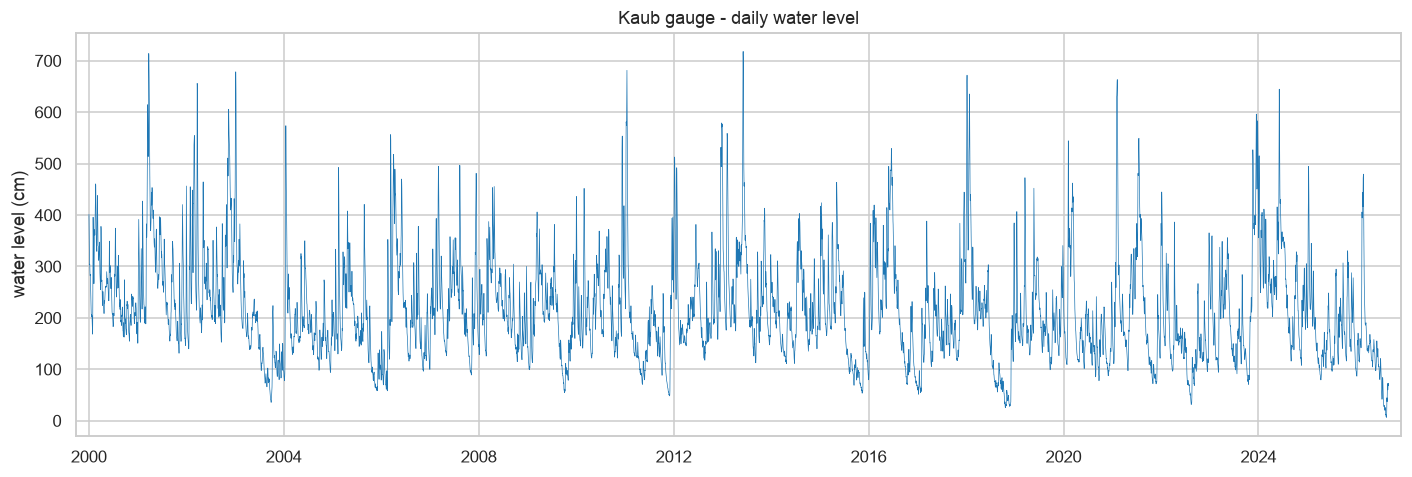

In [8]:
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(df["date"], df[TARGET], lw=0.45, color="#1f77b4")
ax.set_title("Kaub gauge - daily water level")
ax.set_ylabel("water level (cm)")
ax.margins(x=0.01)
plt.tight_layout()
plt.show()

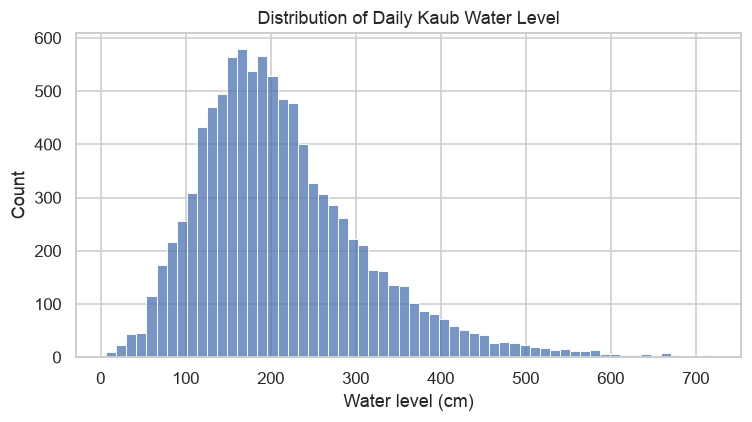

Skewness: 1.138


In [9]:
# Distribution of water level
plt.figure(figsize=(7, 4))

sns.histplot(
    df[TARGET],
    bins=60,
    color="#4c72b0"
)

plt.title("Distribution of Daily Kaub Water Level")
plt.xlabel("Water level (cm)")
plt.ylabel("Count")

plt.tight_layout()
plt.show()

print(f"Skewness: {df[TARGET].skew():.3f}")

### 2.1 Extremes

The low tail is the commercially relevant one - it is where loading restrictions bite - so
it deserves more scrutiny than the flood tail.

In [10]:
cols = ["date", TARGET, "water_level_min", "water_level_max",
        "precipitation_sum", "temperature_mean"]
print("--- 10 lowest days")
display(df.nsmallest(10, TARGET)[cols].reset_index(drop=True))
print("--- 10 highest days")
display(df.nlargest(10, TARGET)[cols].reset_index(drop=True))

--- 10 lowest days


,date,water_level_mean,water_level_min,water_level_max,precipitation_sum,temperature_mean
0,2026-08-17,6.416667,5.00,9.00,2.3,19.383333
1,2026-08-16,6.739583,6.00,8.00,1.8,24.308333
2,2026-08-15,8.052083,6.00,10.25,0.0,28.908333
3,2026-08-14,8.135417,6.00,12.00,0.0,28.362500
4,2026-08-12,11.322917,10.00,13.00,0.0,23.100000
5,2026-08-13,11.916667,10.50,13.50,0.0,25.404167
6,2026-08-18,11.958333,9.00,14.75,2.7,19.308333
7,2026-08-19,13.906250,11.00,21.75,14.0,20.375000
8,2026-08-11,14.614583,13.75,16.50,0.0,22.166667
9,2026-08-10,16.510417,15.50,19.00,0.0,26.183333


--- 10 highest days


,date,water_level_mean,water_level_min,water_level_max,precipitation_sum,temperature_mean
0,2013-06-05,718.145833,716.50,719.00,0.4,16.058333
1,2001-03-25,714.130435,710.00,716.25,3.3,8.075000
2,2013-06-04,714.125000,710.25,716.00,0.0,12.916667
3,2001-03-26,709.437500,703.00,714.50,0.0,3.041667
4,2013-06-06,705.718750,690.25,716.25,0.0,16.850000
5,2001-03-27,693.229167,684.25,702.50,0.0,3.462500
6,2001-03-24,690.104167,660.00,709.00,4.0,11.062500
7,2011-01-16,681.364583,669.25,688.00,0.0,6.195833
8,2013-06-03,678.583333,639.50,709.50,0.0,10.870833
9,2003-01-06,678.406250,673.75,680.00,0.0,-1.966667


### 2.2 Are the record lows real?

The minimum sits far below the widely reported 2022 drought low of roughly 30 cm, which is
exactly the kind of value that turns out to be a sentinel or a datum shift rather than
water. Check it against the untouched 15-minute source rather than the aggregate.

In [11]:
raw = pd.read_csv(
    RAW_PATH, sep=";",
    dtype={"value": "float64"},
    parse_dates=["timestamp"], date_format="%Y-%m-%d %H:%M",
)
print("raw readings:", len(raw))
print(raw["value"].describe().to_string())
print()
print("non-positive readings:", int((raw["value"] <= 0).sum()))
print("readings below 20 cm :", int((raw["value"] < 20).sum()))

# a sentinel would show up as a few repeated exact values at the bottom
print("10 smallest distinct raw values:", np.sort(raw["value"].unique())[:10])

raw readings: 935128
count    935128.000000
mean        214.464213
std         100.964137
min           5.000000
25%         145.000000
50%         197.000000
75%         265.000000
max         719.000000

non-positive readings: 0
readings below 20 cm : 1063
10 smallest distinct raw values: [ 5.  6.  7.  8.  9. 10. 11. 12. 13. 14.]


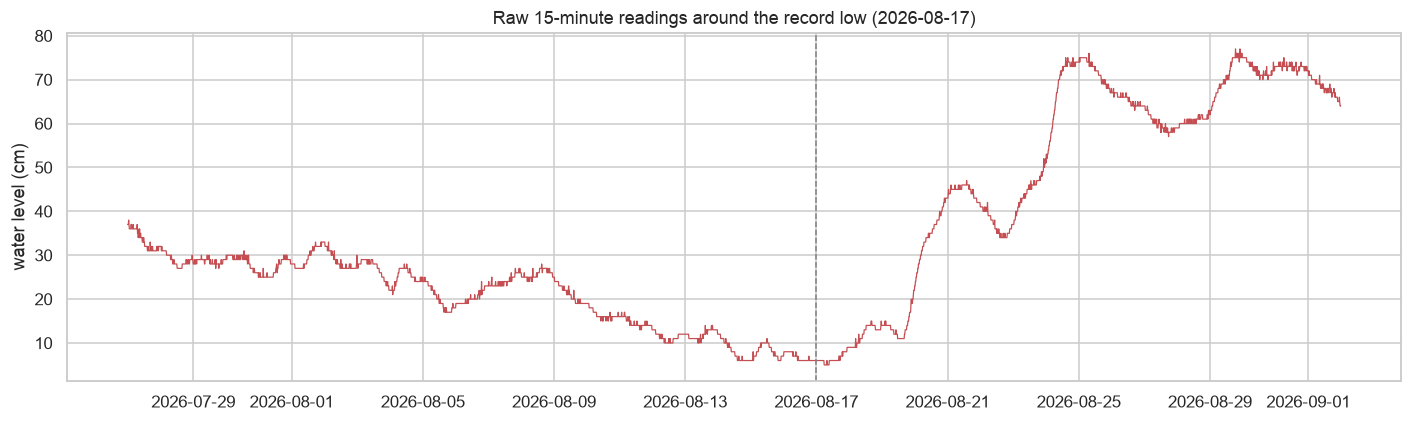

In [12]:
low_date = df.loc[df[TARGET].idxmin(), "date"]
window = raw[(raw["timestamp"] >= low_date - pd.Timedelta(days=21))
             & (raw["timestamp"] <= low_date + pd.Timedelta(days=21))]

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(window["timestamp"], window["value"], lw=0.8, color="#c44e52")
ax.axvline(low_date, ls="--", lw=1, color="grey")
ax.set_title(f"Raw 15-minute readings around the record low ({low_date.date()})")
ax.set_ylabel("water level (cm)")
plt.tight_layout()
plt.show()

**Verdict.** The lows survive the check. There is no sentinel signature - the smallest
distinct raw values run as consecutive integers (5, 6, 7, 8, ...) rather than clustering on
a repeated placeholder, no reading is zero or negative, and the 15-minute trace descends and
recovers smoothly rather than dropping to a flat floor. The record is therefore internally
consistent, but the August 2026 minimum is far below anything else in 26 years - it is worth
one confirmation against the WSV published record before it is used to anchor the low-water
regime of a model, since a gauge datum change would look exactly like this.

## 3. Temporal structure

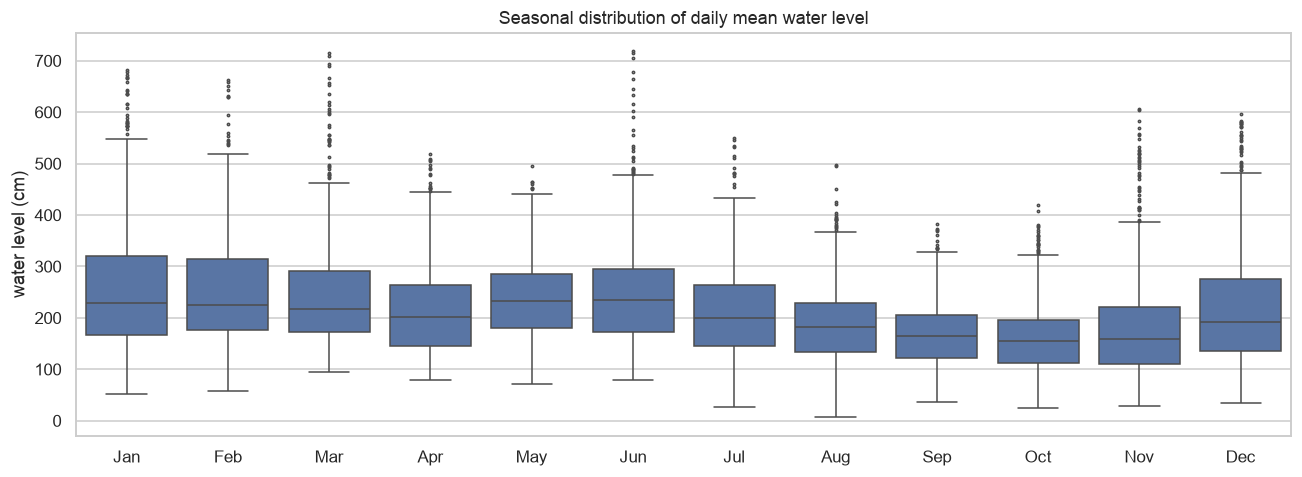

,median,mean,min
month,,,
1,228.6,253.5,51.4
2,224.8,252.4,58.2
3,218.2,244.1,94.1
4,200.9,216.9,79.3
5,232.1,234.9,70.6
6,234.9,248.6,80.1
7,199.0,209.3,26.8
8,182.1,185.3,6.4
9,164.0,168.5,35.6


In [13]:
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["dayofyear"] = df["date"].dt.dayofyear

MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
          "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

fig, ax = plt.subplots(figsize=(12, 4.5))
sns.boxplot(data=df, x="month", y=TARGET, ax=ax, color="#4c72b0", fliersize=1.5)
ax.set_xticks(range(12), MONTHS)
ax.set_title("Seasonal distribution of daily mean water level")
ax.set_xlabel("")
ax.set_ylabel("water level (cm)")
plt.tight_layout()
plt.show()

df.groupby("month")[TARGET].agg(["median", "mean", "min"]).round(1)

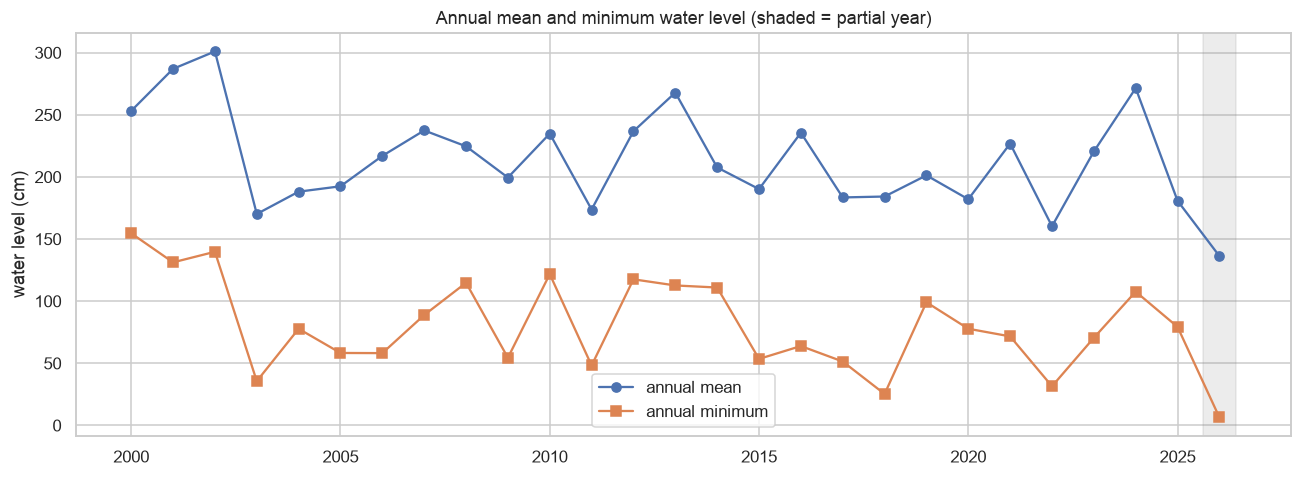

partial years: [2026]


In [14]:
annual = df.groupby("year")[TARGET].agg(["mean", "min", "max", "size"])
partial = annual.index[annual["size"] < 365].tolist()

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(annual.index, annual["mean"], marker="o", label="annual mean")
ax.plot(annual.index, annual["min"], marker="s", label="annual minimum")
for y in partial:
    ax.axvspan(y - 0.4, y + 0.4, color="grey", alpha=0.15)
ax.set_title("Annual mean and minimum water level (shaded = partial year)")
ax.set_ylabel("water level (cm)")
ax.legend()
plt.tight_layout()
plt.show()

print("partial years:", partial)

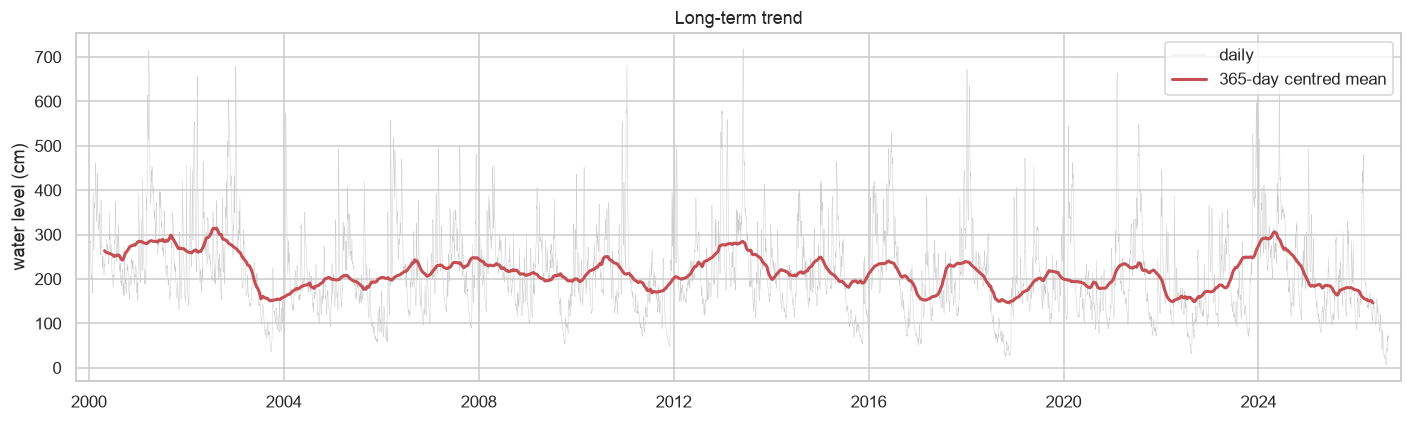

In [15]:
s = df.set_index("date")[TARGET]

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(s.index, s, lw=0.3, color="#cccccc", label="daily")
ax.plot(s.index, s.rolling(365, center=True, min_periods=300).mean(),
        lw=2, color="#c44e52", label="365-day centred mean")
ax.set_title("Long-term trend")
ax.set_ylabel("water level (cm)")
ax.legend()
ax.margins(x=0.01)
plt.tight_layout()
plt.show()

### 3.1 Climatology vs. drought years

A day-of-year percentile band shows what a "normal" year looks like and how far the notable
drought years departed from it.

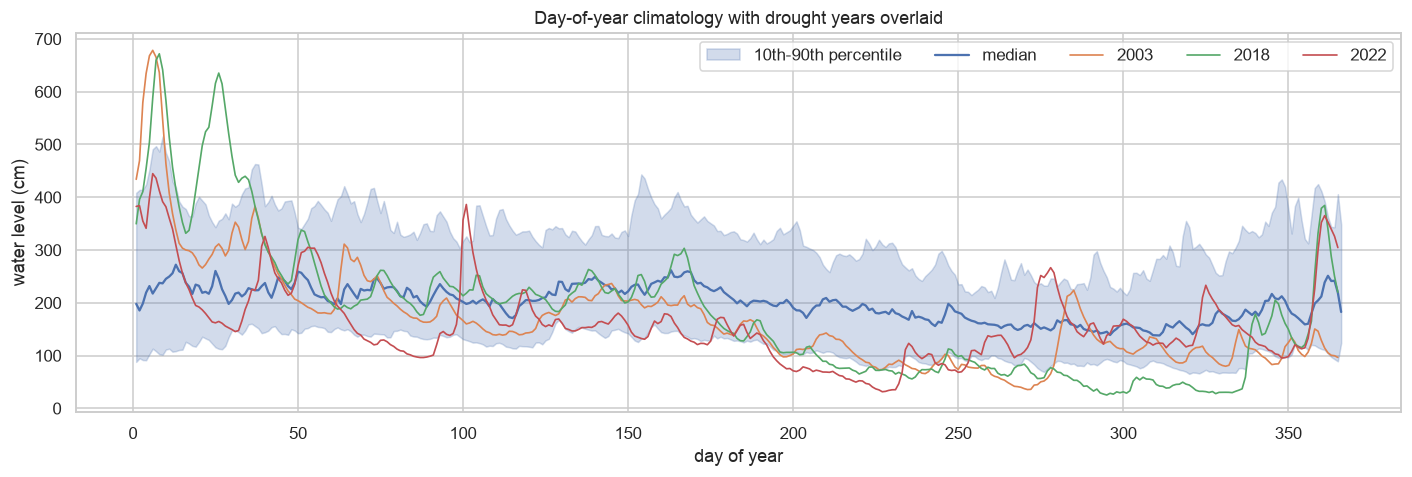

In [16]:
clim = df.groupby("dayofyear")[TARGET].quantile([0.1, 0.5, 0.9]).unstack()

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.fill_between(clim.index, clim[0.1], clim[0.9], alpha=0.25,
                color="#4c72b0", label="10th-90th percentile")
ax.plot(clim.index, clim[0.5], color="#4c72b0", lw=1.5, label="median")

for year, colour in [(2003, "#dd8452"), (2018, "#55a868"), (2022, "#c44e52")]:
    sub = df[df["year"] == year]
    if len(sub):
        ax.plot(sub["dayofyear"], sub[TARGET], lw=1.1, color=colour, label=str(year))

ax.set_title("Day-of-year climatology with drought years overlaid")
ax.set_xlabel("day of year")
ax.set_ylabel("water level (cm)")
ax.legend(ncol=5)
plt.tight_layout()
plt.show()

### 3.2 Persistence

River stage is strongly autocorrelated. Before any model is built, quantify how much of
tomorrow is already explained by today - that is the bar a useful model has to clear.

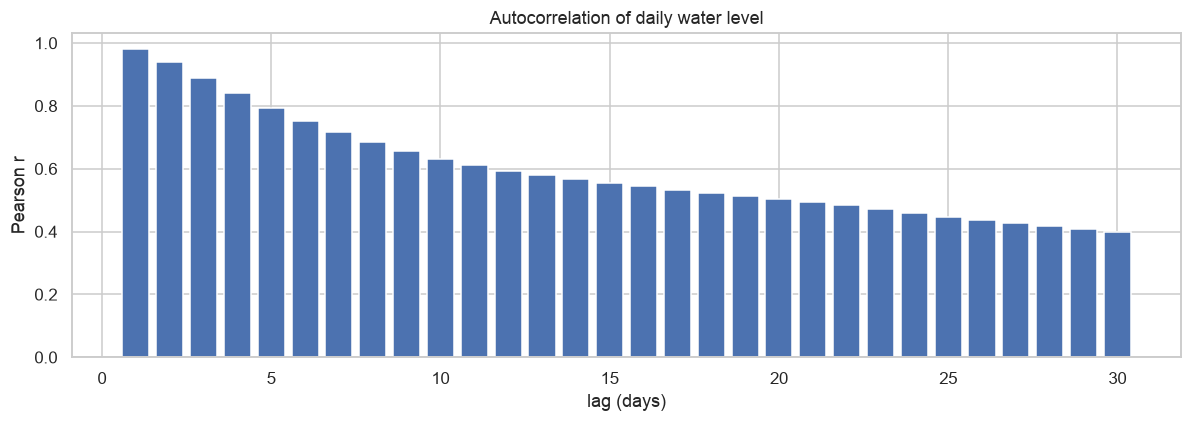

lag  1 day(s): r = 0.9824
lag  2 day(s): r = 0.9405
lag  3 day(s): r = 0.8899
lag  7 day(s): r = 0.7164
lag 14 day(s): r = 0.5670
lag 30 day(s): r = 0.3976


In [17]:
lags = range(1, 31)
acf = [s.corr(s.shift(lag)) for lag in lags]

fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(list(lags), acf, color="#4c72b0")
ax.set_title("Autocorrelation of daily water level")
ax.set_xlabel("lag (days)")
ax.set_ylabel("Pearson r")
plt.tight_layout()
plt.show()

for lag in (1, 2, 3, 7, 14, 30):
    print(f"lag {lag:2d} day(s): r = {s.corr(s.shift(lag)):.4f}")

In [18]:
# Persistence baseline: predict tomorrow = today. This is the number 03. baseline_model
# has to beat for a 1-day horizon.
delta = s.diff().dropna()
print(f"persistence MAE : {delta.abs().mean():.2f} cm")
print(f"persistence RMSE: {np.sqrt((delta ** 2).mean()):.2f} cm")
print(f"target std      : {s.std():.2f} cm")
print()

for horizon in (1, 3, 7, 14):
    err = (s - s.shift(horizon)).dropna()
    print(f"horizon {horizon:2d}d -> persistence MAE {err.abs().mean():6.2f} cm, "
          f"RMSE {np.sqrt((err ** 2).mean()):6.2f} cm")

persistence MAE : 11.97 cm
persistence RMSE: 18.89 cm
target std      : 100.78 cm

horizon  1d -> persistence MAE  11.97 cm, RMSE  18.89 cm
horizon  3d -> persistence MAE  30.92 cm, RMSE  47.27 cm
horizon  7d -> persistence MAE  52.20 cm, RMSE  75.87 cm
horizon 14d -> persistence MAE  66.81 cm, RMSE  93.73 cm


## 4. Weather features

In [19]:
df[WEATHER_COLS].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
temperature_mean,9740.0,10.95,7.14,-10.43,5.36,10.92,16.58,31.63
humidity_mean,9740.0,78.09,11.65,25.33,70.38,79.50,87.25,99.71
precipitation_sum,9740.0,1.85,3.41,0.00,0.00,0.20,2.30,38.40
rain_sum,9740.0,1.72,3.32,0.00,0.00,0.20,2.00,38.40
snowfall_sum,9740.0,0.10,0.52,0.00,0.00,0.00,0.00,12.81
pressure_mean,9740.0,1016.77,8.68,977.21,1011.70,1016.97,1022.28,1046.67
wind_speed_mean,9740.0,11.14,4.89,1.71,7.45,10.28,13.92,37.71


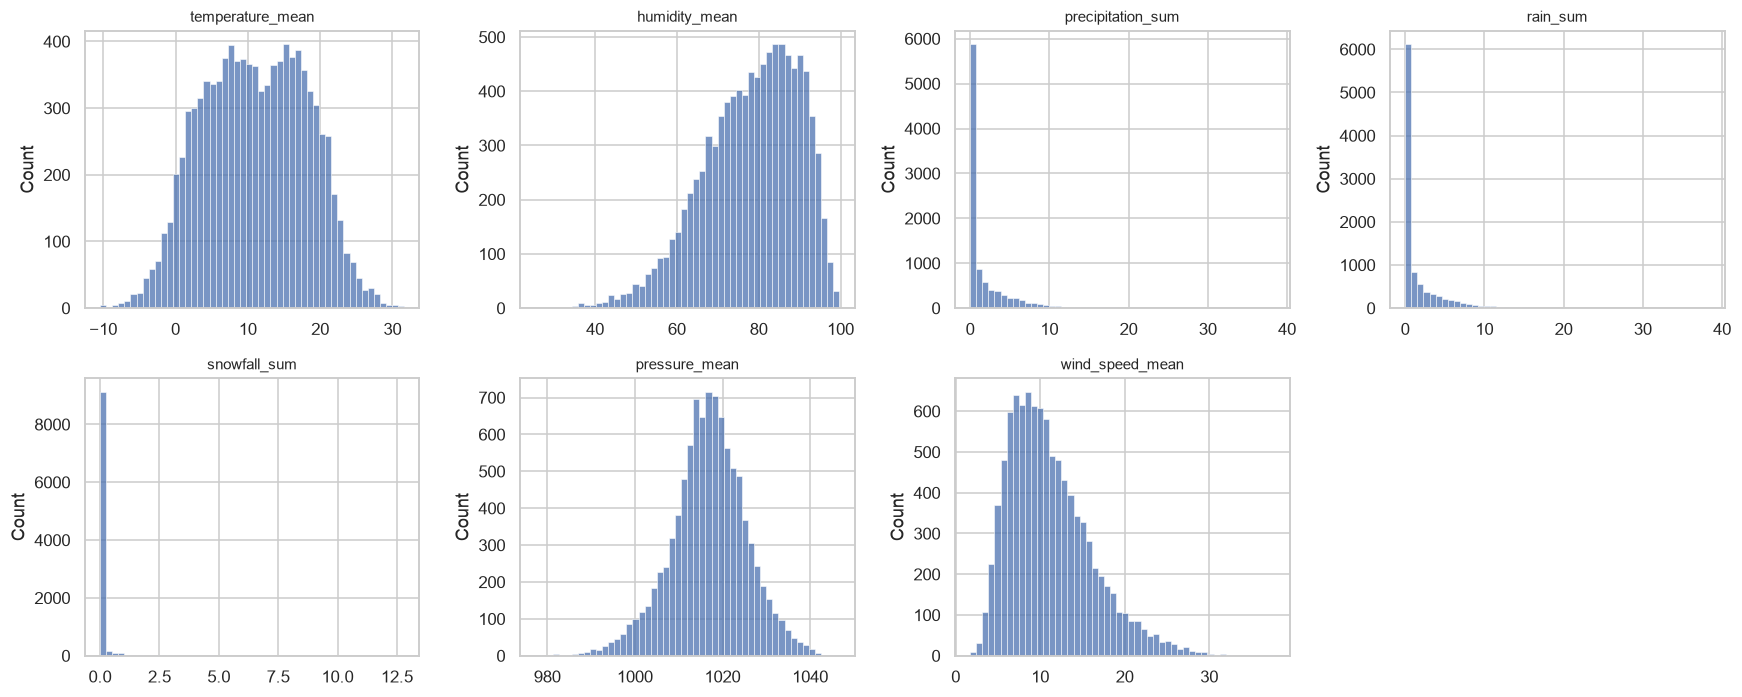

In [20]:
fig, axes = plt.subplots(2, 4, figsize=(16, 6.5))
for ax, col in zip(axes.ravel(), WEATHER_COLS):
    sns.histplot(df[col], bins=50, ax=ax, color="#4c72b0")
    ax.set_title(col, fontsize=10)
    ax.set_xlabel("")
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

### 4.1 Precipitation sanity

`precipitation_sum`, `rain_sum` and `snowfall_sum` come from the same Open-Meteo request.
Open-Meteo reports precipitation and rain in mm but snowfall in **cm of fresh snow**, so the
three are not on a common scale and must not be summed or used together uncritically.

In [21]:
print(f"dry days (precipitation_sum == 0): {(df['precipitation_sum'] == 0).mean():.1%}")
print(f"days with any snowfall           : {(df['snowfall_sum'] > 0).mean():.1%}")
print()

gap = df["precipitation_sum"] - df["rain_sum"]
print(f"precipitation - rain: max {gap.max():.2f}, min {gap.min():.2f}")

snowy = df[df["snowfall_sum"] > 0]
ratio = (gap[snowy.index] / snowy["snowfall_sum"])
ratio = ratio.replace([np.inf, -np.inf], np.nan).dropna()
print(f"(precip - rain) / snowfall on snowy days: median {ratio.median():.2f} "
      f"[{ratio.quantile(0.1):.2f}, {ratio.quantile(0.9):.2f}]")
print(f"implied snowfall per mm of snow-water-equivalent: {1 / ratio.median():.2f} cm/mm")
print("-> the ratio pins to a fixed constant, not to 1.0: snowfall is on a different")
print("   scale (cm of snow) from precipitation and rain (mm of water), so")
print("   rain_sum + snowfall_sum is NOT a valid total precipitation.")
print("   The snow contribution is already inside precipitation_sum as water equivalent.")
print()
print(f"corr(precipitation_sum, rain_sum) = {df['precipitation_sum'].corr(df['rain_sum']):.4f}")

dry days (precipitation_sum == 0): 42.9%
days with any snowfall           : 8.8%

precipitation - rain: max 18.30, min 0.00
(precip - rain) / snowfall on snowy days: median 1.43 [0.62, 1.43]
implied snowfall per mm of snow-water-equivalent: 0.70 cm/mm
-> the ratio pins to a fixed constant, not to 1.0: snowfall is on a different
   scale (cm of snow) from precipitation and rain (mm of water), so
   rain_sum + snowfall_sum is NOT a valid total precipitation.
   The snow contribution is already inside precipitation_sum as water equivalent.

corr(precipitation_sum, rain_sum) = 0.9767


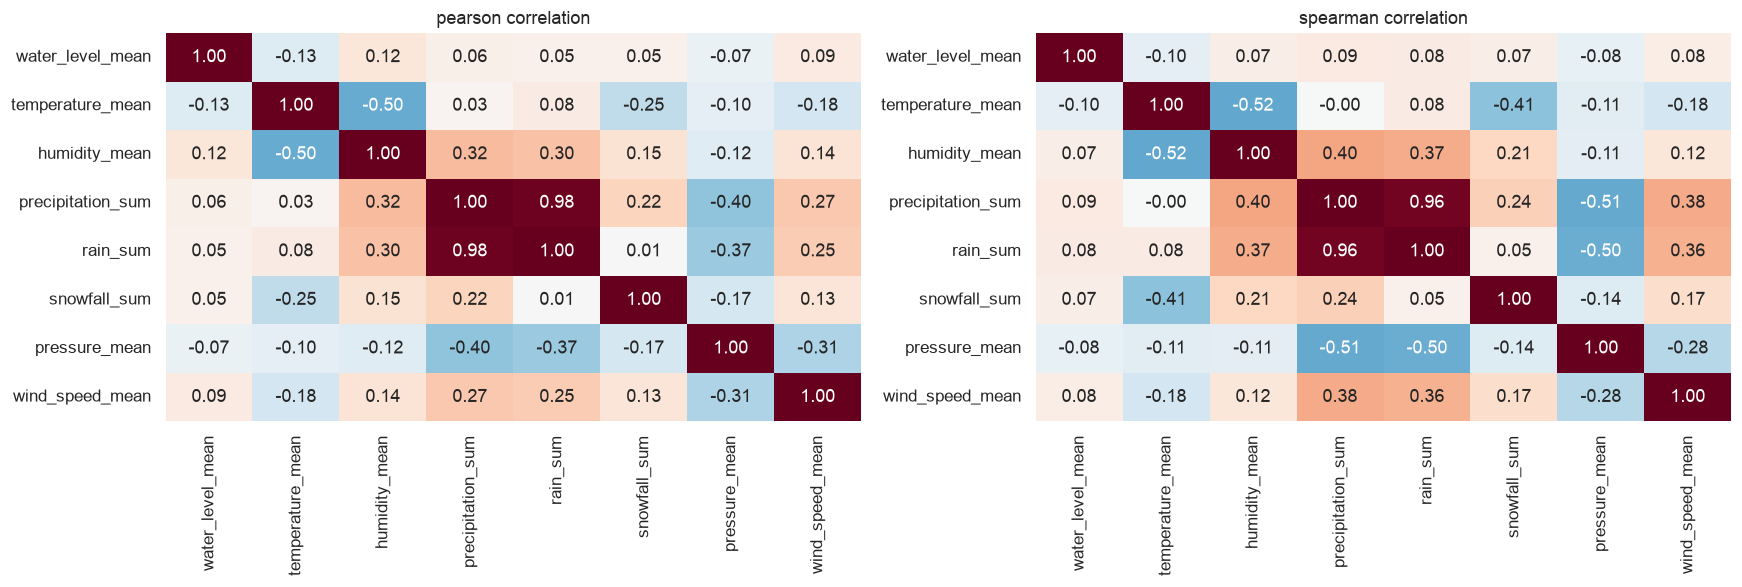

In [22]:
corr_cols = [TARGET] + WEATHER_COLS
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
for ax, method in zip(axes, ["pearson", "spearman"]):
    sns.heatmap(df[corr_cols].corr(method=method), annot=True, fmt=".2f",
                cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax, cbar=False)
    ax.set_title(f"{method} correlation")
plt.tight_layout()
plt.show()

## 5. Rainfall to water level: it is the accumulation that matters

Same-day rainfall barely moves the Rhine at Kaub - the catchment integrates weeks of
precipitation. Find the accumulation window that actually tracks the level. (Because of
caveat 1 at the top, only *daily-and-coarser* lags are trustworthy here.)

,window_days,pearson_r,spearman_r
0,1,0.060,0.091
1,3,0.181,0.190
2,7,0.390,0.384
3,14,0.489,0.499
4,30,0.523,0.528
5,60,0.498,0.497
6,90,0.409,0.409
7,120,0.353,0.352
8,180,0.349,0.337
9,365,0.230,0.206


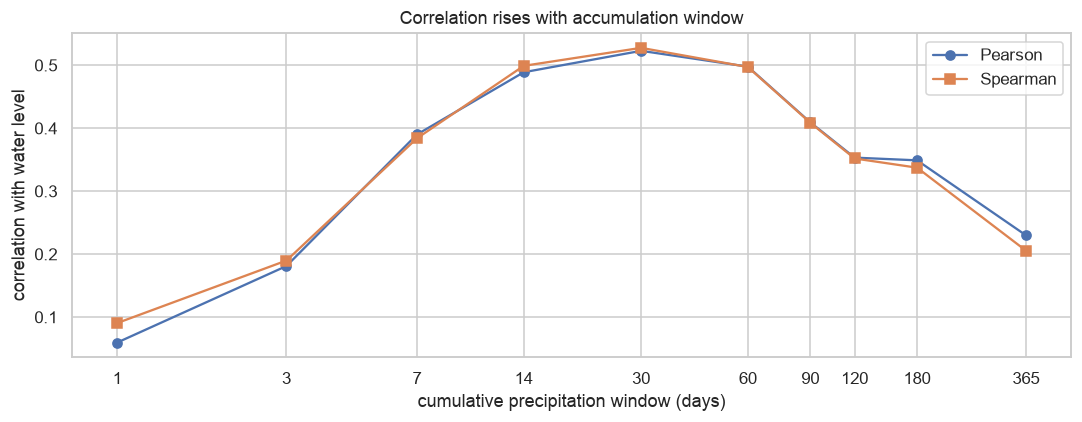

In [23]:
d = df.set_index("date")

rows = []
for w in [1, 3, 7, 14, 30, 60, 90, 120, 180, 365]:
    roll = d["precipitation_sum"].rolling(w).sum()
    rows.append({
        "window_days": w,
        "pearson_r": roll.corr(d[TARGET]),
        "spearman_r": roll.corr(d[TARGET], method="spearman"),
    })
window_corr = pd.DataFrame(rows)
display(window_corr.round(3))

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(window_corr["window_days"], window_corr["pearson_r"], marker="o", label="Pearson")
ax.plot(window_corr["window_days"], window_corr["spearman_r"], marker="s", label="Spearman")
ax.set_xscale("log")
ax.set_xticks(window_corr["window_days"], window_corr["window_days"].astype(str))
ax.set_xlabel("cumulative precipitation window (days)")
ax.set_ylabel("correlation with water level")
ax.set_title("Correlation rises with accumulation window")
ax.legend()
plt.tight_layout()
plt.show()

best accumulation window: 30 days


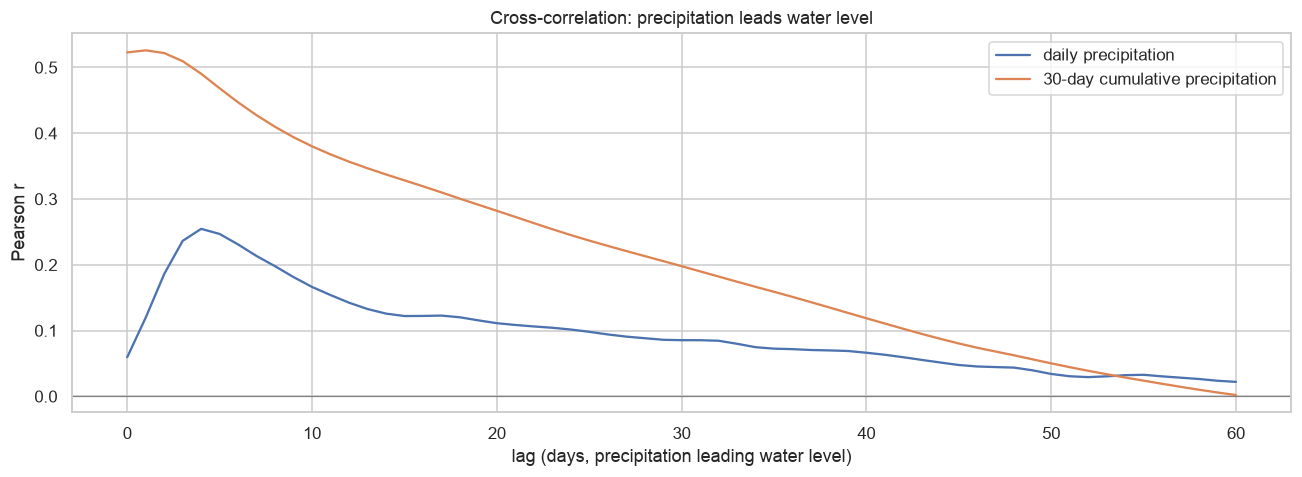

peak lag, daily precip: 4 days, r = 0.255
peak lag, 30-day cumulative: 1 days, r = 0.526


In [24]:
best_w = int(window_corr.loc[window_corr["spearman_r"].idxmax(), "window_days"])
print("best accumulation window:", best_w, "days")

lags = range(0, 61)
cc_daily = [d["precipitation_sum"].shift(lag).corr(d[TARGET]) for lag in lags]
roll_best = d["precipitation_sum"].rolling(best_w).sum()
cc_roll = [roll_best.shift(lag).corr(d[TARGET]) for lag in lags]

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(list(lags), cc_daily, label="daily precipitation")
ax.plot(list(lags), cc_roll, label=f"{best_w}-day cumulative precipitation")
ax.axhline(0, color="grey", lw=0.8)
ax.set_xlabel("lag (days, precipitation leading water level)")
ax.set_ylabel("Pearson r")
ax.set_title("Cross-correlation: precipitation leads water level")
ax.legend()
plt.tight_layout()
plt.show()

print("peak lag, daily precip:", int(np.argmax(cc_daily)), "days, r =", round(max(cc_daily), 3))
print(f"peak lag, {best_w}-day cumulative:", int(np.argmax(cc_roll)),
      "days, r =", round(max(cc_roll), 3))

In [25]:
peak_table = pd.DataFrame({
    "Feature": [
        "Daily precipitation",
        f"{best_w}-day cumulative precipitation"
    ],
    "Peak lag (days)": [
        int(np.argmax(cc_daily)),
        int(np.argmax(cc_roll))
    ],
    "Pearson r": [
        max(cc_daily),
        max(cc_roll)
    ]
})

peak_table["Pearson r"] = peak_table["Pearson r"].round(3)

peak_table

,Feature,Peak lag (days),Pearson r
0,Daily precipitation,4,0.255
1,30-day cumulative precipitation,1,0.526


In [26]:
# Temperature enters through evaporation and snowmelt, so it should also act with a lag.
for col in ["temperature_mean", "humidity_mean", "pressure_mean"]:
    smoothed = d[col].rolling(30).mean()
    best = max(range(0, 91), key=lambda l: abs(smoothed.shift(l).corr(d[TARGET])))
    r = smoothed.shift(best).corr(d[TARGET])
    print(f"{col:18s}: 30-day mean, best lag {best:2d}d, r = {r:+.3f}")

temperature_mean  : 30-day mean, best lag 46d, r = -0.293
humidity_mean     : 30-day mean, best lag 90d, r = +0.280
pressure_mean     : 30-day mean, best lag  1d, r = -0.382


## 6. Low-water exposure

The business question is not "what is the level" but "how often, and for how long, is the
river below the level at which a barge must be part-loaded". Thresholds below are
placeholders - **replace them with the operator's actual loading limits** before these
numbers are used for planning.

In [27]:
THRESHOLDS = [40, 78, 100, 150]  # cm - placeholder operating thresholds


def longest_run(mask: pd.Series) -> int:
    if not mask.any():
        return 0
    return int(mask.groupby((~mask).cumsum()).sum().max())


summary = []
for t in THRESHOLDS:
    below = df[TARGET] < t
    summary.append({
        "threshold_cm": t,
        "days_below": int(below.sum()),
        "pct_of_record": round(below.mean() * 100, 2),
        "longest_streak_days": longest_run(below),
    })
pd.DataFrame(summary)

,threshold_cm,days_below,pct_of_record,longest_streak_days
0,40,69,0.71,26
1,78,421,4.32,67
2,100,849,8.72,88
3,150,2652,27.23,148


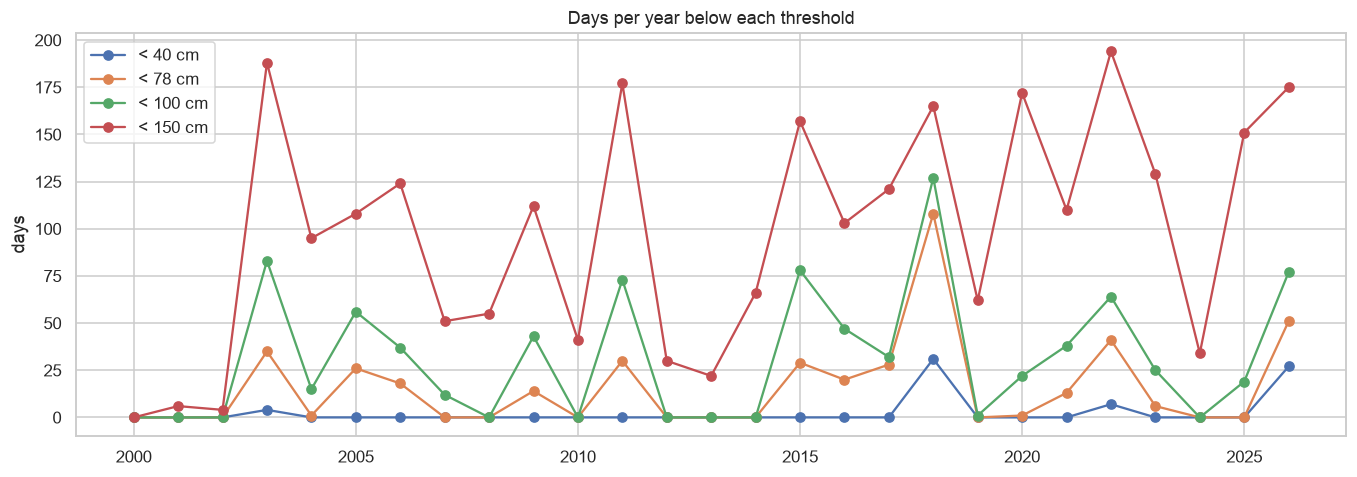

In [28]:
years = sorted(df["year"].unique())

fig, ax = plt.subplots(figsize=(12.5, 4.5))
for t in THRESHOLDS:
    counts = (
        df.assign(below=df[TARGET] < t)
          .groupby("year")["below"].sum()
          .reindex(years, fill_value=0)
    )
    ax.plot(years, counts, marker="o", label=f"< {t} cm")
ax.set_title("Days per year below each threshold")
ax.set_ylabel("days")
ax.legend()
plt.tight_layout()
plt.show()

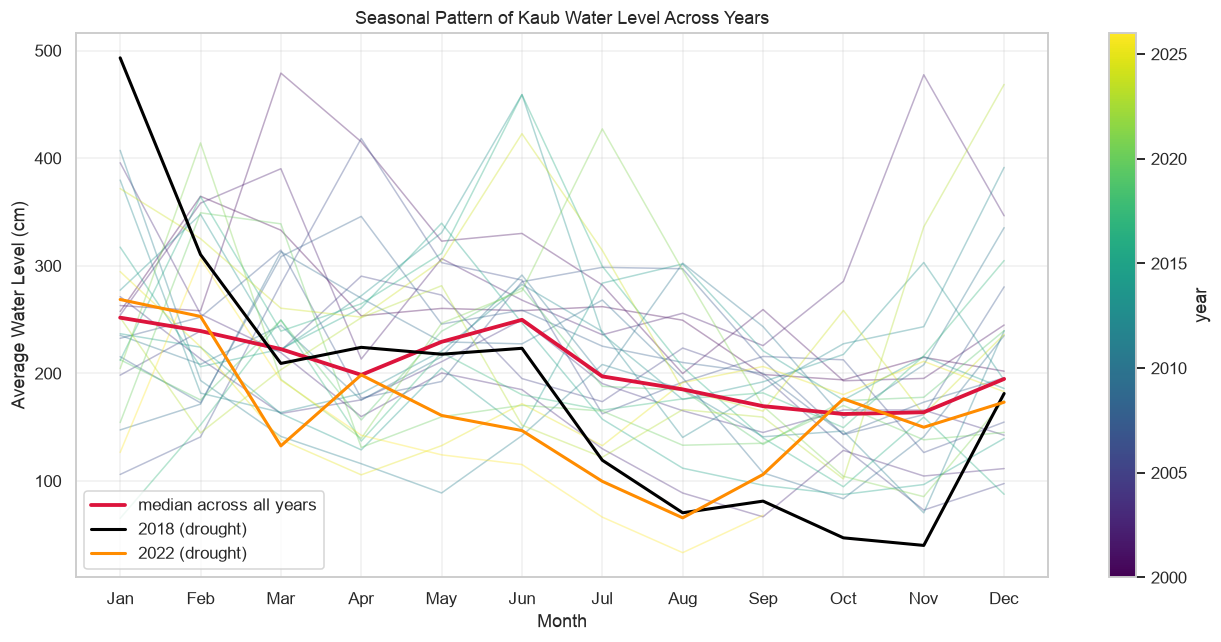

In [29]:
df = pd.read_csv("../data/processed/kaub_water_weather_daily.csv")
df["date"] = pd.to_datetime(df["date"])
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month

monthly = (
    df.groupby(["year", "month"])["water_level_mean"]   # <- was "water_level"
      .mean()
      .reset_index()
)

clim = monthly.groupby("month")["water_level_mean"].median()

fig, ax = plt.subplots(figsize=(12, 6))
years = sorted(monthly["year"].unique())
cmap = plt.get_cmap("viridis")

for i, (year, group) in enumerate(monthly.groupby("year")):
    ax.plot(group["month"], group["water_level_mean"],
            alpha=0.35, lw=1, color=cmap(i / (len(years) - 1)))

ax.plot(clim.index, clim.values, color="crimson", lw=2.5,
        label="median across all years")
for y, c in [(2018, "black"), (2022, "darkorange")]:
    g = monthly[monthly["year"] == y]
    ax.plot(g["month"], g["water_level_mean"], lw=2, color=c, label=f"{y} (drought)")

ax.set_xticks(range(1, 13))
ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_xlabel("Month")
ax.set_ylabel("Average Water Level (cm)")
ax.set_title("Seasonal Pattern of Kaub Water Level Across Years")
ax.grid(alpha=0.3)
ax.legend()

sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(years[0], years[-1]))
fig.colorbar(sm, ax=ax, label="year")
plt.tight_layout()
plt.show()


## 7. What this means for the model

Structural conclusions that hold regardless of the exact numbers above:

- **Persistence is a strong baseline.** Section 3.2 gives the MAE/RMSE that
  `03. baseline_model.ipynb` must beat at each horizon. A model that does not beat
  "tomorrow = today" at 1 day is not yet useful.
- **Use accumulated, lagged precipitation, not same-day rainfall.** Section 5 identifies the
  window and lag that actually carry signal; same-day precipitation is close to useless on
  its own.
- **The target is right-skewed and the low tail is what matters.** Consider modelling
  `log(level)`, or weighting and evaluating errors specifically in the low-water regime,
  rather than optimising plain RMSE over a range dominated by ordinary flows.
- **`rain_sum + snowfall_sum` is not total precipitation** (different units, section 4.1),
  and `rain_sum` is 0.98-correlated with `precipitation_sum` so carrying both is redundant.
  Use `precipitation_sum`, and treat `snowfall_sum` as a separate snowpack proxy.
- **Split chronologically, never randomly.** With lag-1 autocorrelation this high, a random
  train/test split leaks the answer and will report a fantasy score.
- **Fix the timezone handling upstream before trusting sub-daily features.** See caveat 1.